# Forward e backward: como os dados chegam aos pesos

A pergunta do marco M2 do tutorial é: *como os dados chegam aos tensores e aos pesos?* Este notebook
responde com a rede mais simples que aprende a prever o próximo token, o **bigrama neural**
(`src/nano_review/models/bigram.py`). Ela é uma tabela `V x V` de números livres: a linha `i` guarda
os logits do token que vem depois do token `i`.

O ciclo mostrado aqui é **o mesmo** que vai treinar o Transformer:

1. **forward:** tokens -> logits -> probabilidades;
2. **loss:** quão surpreso o modelo ficou com o token certo (entropia cruzada);
3. **backward:** quanto cada peso contribuiu para essa surpresa (gradiente);
4. **atualização:** mexer cada peso um pouco na direção que diminui a loss.

Cada passo é conferido com uma conta feita à mão.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from tokenizers import Tokenizer

from nano_review.data.dataset import IGNORE_INDEX, ReviewDataset, make_loader
from nano_review.models.bigram import BigramLanguageModel
from nano_review.models.loss import language_model_loss, manual_loss_gradient
from nano_review.reproducibility import set_seed

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Mesmo padrão visual da EDA. Duas séries: azul e laranja, os dois primeiros tons da paleta.
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.6,
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "font.size": 10,
        "figure.dpi": 100,
        "savefig.dpi": 150,
        "savefig.bbox": "tight",
    }
)

set_seed(42)
tokenizer = Tokenizer.from_file(str(ROOT / "models" / "tokenizer.json"))
VOCAB = tokenizer.get_vocab_size()

# Uma amostra do treino e da validação: o objetivo aqui é ver o mecanismo, não treinar até o fim.
train = pd.read_parquet(ROOT / "data" / "curated" / "train.parquet").sample(20_000, random_state=0)
validation = pd.read_parquet(ROOT / "data" / "curated" / "validation.parquet").sample(
    5_000, random_state=0
)
train_set = ReviewDataset(train, tokenizer, block_size=128)
validation_set = ReviewDataset(validation, tokenizer, block_size=128)
print("vocabulário:", VOCAB, "| resenhas de treino:", len(train_set))

vocabulário: 4000 | resenhas de treino: 19536


## 1. Um lote: texto vira tensor

O DataLoader entrega dois tensores do mesmo tamanho `(B, T)`: a entrada `x` e o alvo `y`, que é `x`
deslocado de uma posição. Em cada posição, o modelo lê o token de `x` e precisa prever o de `y`.
`-100` marca as posições que não contam: a da nota, que é dada e não prevista, e o padding.

In [2]:
x, y = next(iter(make_loader(train_set, tokenizer, batch_size=8, shuffle=True, seed=0)))
print("x:", tuple(x.shape), x.dtype, "| y:", tuple(y.shape))

row = 0
length = int((y[row] != IGNORE_INDEX).sum()) + 1
pd.DataFrame(
    {
        "lê (x)": [tokenizer.id_to_token(int(i)) for i in x[row, :length]],
        "deve prever (y)": [
            "(não conta)" if int(t) == IGNORE_INDEX else tokenizer.id_to_token(int(t))
            for t in y[row, :length]
        ],
    }
).rename_axis("posição")

x: (8, 15) torch.int64 | y: (8, 15)


,lê (x),deve prever (y)
posição,,
0,<bos>,(não conta)
1,<nota_5>,▁Chegou
2,▁Chegou,▁em
3,▁em,▁perfeito
4,▁perfeito,▁estado
5,▁estado,","
6,",",▁recomendo
7,▁recomendo,.
8,.,▁Chegou


## 2. Forward

O forward do bigrama é uma consulta à tabela: cada posição pega a linha do seu token. Os logits viram
probabilidades pelo softmax. Antes de qualquer treino, a tabela tem números pequenos e quase iguais,
então o modelo dá ~1/V a cada token, e a loss esperada é **ln(V)**. Conferir isso é o primeiro teste
de sanidade de qualquer modelo de linguagem: uma loss inicial muito acima de ln(V) indica uma
inicialização ruim, e uma muito abaixo, um bug (por exemplo, o alvo vazando para a entrada).

In [3]:
model = BigramLanguageModel(VOCAB)
logits = model(x)
probabilities = torch.softmax(logits, dim=-1)
loss = language_model_loss(logits, y)

print("parâmetros:", f"{sum(p.numel() for p in model.parameters()):,}".replace(",", "."))
print("logits:", tuple(logits.shape), "= (lote, posições, vocabulário)")
print("cada linha de probabilidades soma:", round(float(probabilities[0, 0].sum().detach()), 4))
print(f"loss inicial: {loss.item():.3f} | ln(V) = {math.log(VOCAB):.3f}")

parâmetros: 16.000.000
logits: (8, 15, 4000) = (lote, posições, vocabulário)
cada linha de probabilidades soma: 1.0
loss inicial: 8.300 | ln(V) = 8.294


## 3. Backward, conferido à mão

O `loss.backward()` calcula o gradiente da loss em relação a cada peso. Na primeira etapa da volta,
em relação aos logits, a conta tem forma fechada:

$$\frac{\partial\, \text{loss}}{\partial\, \text{logits}} = \frac{\text{softmax}(\text{logits}) - \text{one\_hot}(\text{alvo})}{N}$$

O gradiente empurra **para cima** o logit do token certo e **para baixo** todos os outros, cada um na
proporção da probabilidade que o modelo deu a ele. `N` é o número de posições que contam.

A seguir, o mesmo gradiente calculado pelo autograd e pela fórmula (`manual_loss_gradient` em
`src/nano_review/models/loss.py`).

In [4]:
logits = model(x)
logits.retain_grad()  # guarda o gradiente de um tensor intermediário, só para inspecionar
loss = language_model_loss(logits, y)
model.zero_grad()
loss.backward()

manual = manual_loss_gradient(logits, y)
assert logits.grad is not None
print("maior diferença autograd x fórmula:", float((logits.grad - manual).abs().max()))
print("posições ignoradas receberam gradiente?", bool(logits.grad[y == IGNORE_INDEX].any()))

maior diferença autograd x fórmula: 9.313225746154785e-10
posições ignoradas receberam gradiente? False


Da camada de logits, o gradiente desce para a tabela pela regra da cadeia. Como o forward foi só uma
consulta, a linha `i` da tabela recebe a soma dos gradientes das posições em que o token `i`
apareceu na entrada **numa posição que conta**. Linhas de tokens que não estavam no lote recebem
zero: este lote só ensina sobre os tokens que contém. `<bos>` e `<pad>` também ficam com zero,
porque só aparecem em posições ignoradas.

In [5]:
table_gradient = model.table.weight.grad
assert table_gradient is not None
rows_with_gradient = int((table_gradient.abs().sum(dim=1) > 0).sum())
counts = y != IGNORE_INDEX
print("tokens distintos na entrada do lote:              ", int(x.unique().numel()))
print("... só nas posições que contam (sem <bos>, <pad>):", int(x[counts].unique().numel()))
print("linhas da tabela com gradiente:                   ", rows_with_gradient, "de", VOCAB)

tokens distintos na entrada do lote:               84
... só nas posições que contam (sem <bos>, <pad>): 82
linhas da tabela com gradiente:                    82 de 4000


## 4. Atualização: descida do gradiente à mão, e depois com AdamW

A atualização mais simples é `peso -= taxa * gradiente`, sem otimizador nenhum. O laço abaixo faz
isso 300 vezes com lotes diferentes. A seguir, o mesmo número de passos com o **AdamW**, o
otimizador que o Transformer vai usar.

A taxa do SGD (200) parece enorme, e é de propósito. Cada linha da tabela recebe só o gradiente das
poucas posições em que o token dela apareceu, dividido pelas ~1.500 posições do lote, então os
gradientes são minúsculos. O AdamW resolve isso ajustando o tamanho do passo **para cada peso**, a
partir do histórico dos gradientes dele.

In [6]:
def train_bigram(optimizer_name: str, learning_rate: float, steps: int = 300) -> list[float]:
    set_seed(0)
    bigram = BigramLanguageModel(VOCAB)
    optimizer = (
        torch.optim.AdamW(bigram.parameters(), lr=learning_rate)
        if optimizer_name == "adamw"
        else None
    )
    loader = make_loader(train_set, tokenizer, batch_size=64, shuffle=True, seed=0)
    batches = iter(loader)
    losses = []
    for _ in range(steps):
        try:
            x, y = next(batches)
        except StopIteration:
            batches = iter(loader)
            x, y = next(batches)
        loss = language_model_loss(bigram(x), y)  # forward + loss
        bigram.zero_grad()
        loss.backward()  # backward
        if optimizer is not None:
            optimizer.step()  # atualização pelo AdamW
        else:
            with torch.no_grad():  # atualização à mão: a conta não entra no grafo do autograd
                for parameter in bigram.parameters():
                    assert parameter.grad is not None
                    parameter.sub_(learning_rate * parameter.grad)
        losses.append(loss.item())
    trained[optimizer_name] = bigram
    return losses


trained: dict[str, BigramLanguageModel] = {}
curves = {"SGD à mão (taxa 200)": train_bigram("sgd", 200.0)}
curves["AdamW (taxa 0,1)"] = train_bigram("adamw", 0.1)
for name, losses in curves.items():
    print(f"{name}: {losses[0]:.2f} -> {sum(losses[-20:]) / 20:.2f} (média dos últimos 20 passos)")

SGD à mão (taxa 200): 8.29 -> 6.25 (média dos últimos 20 passos)
AdamW (taxa 0,1): 8.29 -> 4.77 (média dos últimos 20 passos)


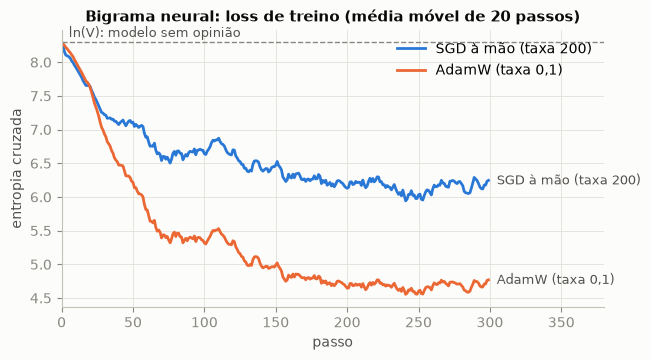

In [7]:
def smooth(values: list[float], window: int = 20) -> list[float]:
    """Média móvel: a loss de um lote oscila muito, e a tendência é o que interessa."""
    return [
        sum(values[max(0, i - window + 1) : i + 1]) / len(values[max(0, i - window + 1) : i + 1])
        for i in range(len(values))
    ]


fig, ax = plt.subplots(figsize=(7, 3.6))
for (name, losses), color in zip(curves.items(), [BLUE, ORANGE], strict=True):
    ax.plot(smooth(losses), color=color, linewidth=2, label=name)
    ax.annotate(
        name,
        (len(losses) - 1, smooth(losses)[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color="#52514e",
        fontsize=9,
    )
ax.axhline(math.log(VOCAB), color="#898781", linewidth=1, linestyle="--")
ax.text(5, math.log(VOCAB) + 0.08, "ln(V): modelo sem opinião", color="#52514e", fontsize=9)
ax.set_title("Bigrama neural: loss de treino (média móvel de 20 passos)")
ax.set_xlabel("passo")
ax.set_ylabel("entropia cruzada")
ax.legend(loc="upper right", frameon=False)
ax.set_xlim(0, 380)
fig.savefig(FIG_DIR / "bigram_training.png")
plt.show()

## 5. Validação

A loss de treino pode cair só porque o modelo decorou os lotes. A loss na **validação**, em resenhas
de produtos que o modelo nunca viu, mostra se ele aprendeu algo que generaliza. `exp(loss)` é a
perplexity **por token BPE**. Ela não se compara com a perplexity **por palavra** do trigrama
(90,2): a conversão para a mesma unidade é feita na Etapa 3, como manda o charter.

In [8]:
@torch.no_grad()
def validation_loss(bigram: BigramLanguageModel) -> float:
    total, count = 0.0, 0
    for x, y in make_loader(validation_set, tokenizer, batch_size=256, shuffle=False, seed=0):
        n = int((y != IGNORE_INDEX).sum())
        total += language_model_loss(bigram(x), y).item() * n  # soma, para ponderar por token
        count += n
    return total / count


rows = []
for name, key in [("SGD à mão", "sgd"), ("AdamW", "adamw")]:
    loss = validation_loss(trained[key])
    rows.append(
        {
            "modelo": name,
            "loss na validação": round(loss, 3),
            "perplexity por token": round(math.exp(loss), 1),
        }
    )
pd.DataFrame(rows).set_index("modelo")

,loss na validação,perplexity por token
modelo,,
SGD à mão,6.363,580.3
AdamW,4.829,125.1


## 6. O que o bigrama aprendeu, e o que ele não consegue aprender

Depois de `<nota_k>`, o bigrama prevê a **primeira** palavra da resenha. É o único lugar em que a
nota influencia alguma coisa: da segunda palavra em diante, ele só enxerga o token anterior.

In [9]:
bigram = trained["adamw"]
rows = {}
for rating in (1, 5):
    token_id = tokenizer.token_to_id(f"<nota_{rating}>")
    top = torch.softmax(bigram.table.weight[token_id], dim=-1).topk(8)
    rows[f"depois de <nota_{rating}>"] = [
        f"{tokenizer.id_to_token(int(i))} ({p:.0%})"
        for p, i in zip(top.values, top.indices, strict=True)
    ]
pd.DataFrame(rows)

,depois de <nota_1>,depois de <nota_5>
0,▁O (11%),▁Produto (12%)
1,▁Não (9%),▁O (9%)
2,▁A (7%),▁Excelente (6%)
3,▁Comprei (6%),▁Muito (5%)
4,▁Produto (6%),▁Ótimo (3%)
5,▁Estou (2%),▁A (3%)
6,▁Ainda (2%),▁produto (3%)
7,▁Como (2%),▁Gostei (3%)


In [10]:
@torch.no_grad()
def sample(bigram: BigramLanguageModel, rating: int, max_tokens: int = 40) -> str:
    ids = [tokenizer.token_to_id("<bos>"), tokenizer.token_to_id(f"<nota_{rating}>")]
    for _ in range(max_tokens):
        probabilities = torch.softmax(bigram.table.weight[ids[-1]], dim=-1)
        next_id = int(torch.multinomial(probabilities, 1))
        if next_id == tokenizer.token_to_id("<eos>"):
            break
        ids.append(next_id)
    return tokenizer.decode(ids, skip_special_tokens=True)


set_seed(1)
for rating in (1, 5):
    for _ in range(3):
        print(f"nota {rating}: {sample(bigram, rating)}")

nota 1: o que dá para mais pelo site e tinha sido mais velh. Vou estabelecido.
nota 1: Recebi o qtação, e fiquei muito bom tempo incrível numa loja está horrível, o produto funciona com umaentou desliga e excelente jogo excelente qualidade .... Te---mail
nota 1: Peteiro disse fone de cinelizmenteena que comple PEA DO PRAZO..muito chateada, já está usando para utilização do demo perfeito estado , leve e eu gostei mt bom recomendo. Caso
nota 5: Exatamenteixestátil positivamenteERICAN caiu o brinquedo Comprarei toda hora, ninguém..
nota 5: Produto de 2 semanas infor secar para mim não tinha o que buscarisopor .
nota 5: Muito satisfeita!


**O que isso mostra**

- Depois de `<nota_1>`, as primeiras palavras mais prováveis são de reclamação; depois de
  `<nota_5>`, de elogio. A nota funciona, **mas só no primeiro token**.
- As amostras são localmente plausíveis (pares de palavras que existem) e perdem o sentido logo em
  seguida, porque o modelo só lembra **um** token. É a mesma limitação do trigrama, com uma janela
  ainda menor.
- O próximo passo, o Transformer (sub-etapa 2.4), troca a tabela por uma rede em que **cada posição
  consulta todas as anteriores** pela atenção, incluindo o token de nota no começo. O ciclo de treino
  é exatamente este: forward, loss, backward, AdamW.